# Street Fighter II — Reinforcement Learning with stable-retro

Train a PPO agent on the Sega Genesis release of **Street Fighter II' - Special
Champion Edition**, straight through `stable-retro`'s Gymnasium environment.

| | |
|---|---|
| Environment | `StreetFighterIISpecialChampionEdition-Genesis-v0` |
| Core | `genesis_plus_gx` (built locally) |
| Observations | `health`, `enemy_health`, `score`, `matches_won`, `continuetimer` |
| Reward | score gain + damage dealt/taken (`scenarios/health.json`) |
| Agent | Stable-Baselines3 PPO, `CnnPolicy`, 84x84 grayscale, 4-frame stack |

Run the cells top to bottom. Total runtime on CPU is ~3-5 minutes with the
default settings; every knob is in the **Configuration** cell.

In [1]:
import os, sys, time
from collections import deque

import numpy as np
import matplotlib.pyplot as plt

# Project helpers (ROM check, per-release save state, wrappers)
HERE = r"D:\PROGRAMS\AI\sf2"
if HERE not in sys.path:
    sys.path.insert(0, HERE)

import stable_retro as retro
import train_sf2

print("stable-retro :", retro.__version__.strip())
print("systems      :", ", ".join(sorted(retro.data.EMU_INFO)))
print("ROM          :", os.path.basename(train_sf2.installed_rom_sha1() or "none"))

stable-retro : 1.0.1
systems      : GameGear, Genesis, SCD, Sms
ROM          : 2a406e2e4743de98785c85322f858abfb8221ae0


## 1. Check the game and its ROM

`stable-retro` ships the integration but not the game. A save state is only
valid for the ROM release it was recorded from, so the state is chosen from the
installed ROM's SHA1 (`ROM_STATE_MAP` in `train_sf2.py`).

In [2]:
GAME = train_sf2.SF2_GAME
GAMES = retro.data.list_games()
assert GAME in GAMES, "SF2 integration missing"

rom_path = retro.data.get_romfile_path(GAME)          # raises if not imported
assert not retro.data.verify_hash(GAME), "ROM hash mismatch - run setup_rom.py"

state = train_sf2.default_state_for() or retro.State.DEFAULT
print("integration :", GAME)
print("ROM         :", rom_path)
print("ROM size    :", f"{os.path.getsize(rom_path):,} bytes")
print("ROM SHA1    :", train_sf2.installed_rom_sha1())
print("save state  :", state)

integration : StreetFighterIISpecialChampionEdition-Genesis-v0
ROM         : D:\PROGRAMS\AI\sf2\stable-retro\stable_retro\../stable_retro/data\stable\StreetFighterIISpecialChampionEdition-Genesis-v0\rom.md
ROM size    : 3,145,728 bytes
ROM SHA1    : 2a406e2e4743de98785c85322f858abfb8221ae0
save state  : MatchStart.Europe


## 2. Look at the raw environment

The unwrapped environment is a `MultiBinary(9..12)` button mask over the Genesis
pad. `reset()` restores the match-start save state, so the fight begins with both
health bars full.

screen    : (200, 256, 3) uint8
actions   : MultiBinary(12)
buttons   : ['B', 'A', 'MODE', 'START', 'UP', 'DOWN', 'LEFT', 'RIGHT', 'C', 'Y', 'X', 'Z']


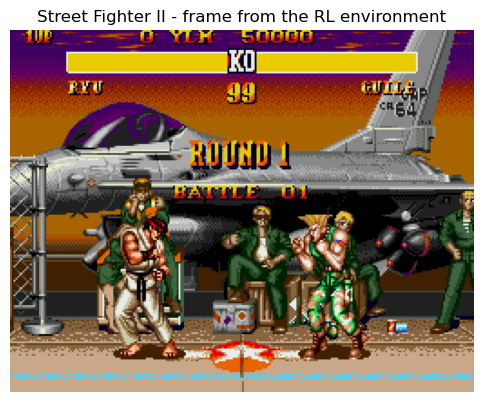

In [3]:
raw = retro.make(
    game=GAME,
    state=state,
    scenario=None,                 # the game's own score-based scenario
    render_mode="rgb_array",
    use_restricted_actions=retro.Actions.FILTERED,
)
obs, info = raw.reset(seed=0)
print("screen    :", obs.shape, obs.dtype)
print("actions   :", raw.action_space)
print("buttons   :", raw.buttons)

plt.figure(figsize=(6, 4.7))
plt.imshow(obs)
plt.title("Street Fighter II - frame from the RL environment")
plt.axis("off")
plt.show()

raw.close()   # stable-retro allows one emulator per process

## 3. The training wrapper stack

Defined once in `train_sf2.py`, reused by the notebook, `verify_setup.py` and the
CLI trainer:

`Discretizer(60 combos)` → `StochasticFrameSkip(4)` → `GrayResize(84x84)` →
`ClipReward` → `TimeLimit`

In [4]:
env = train_sf2.make_env(seed=0, scenario="health", max_episode_steps=1000)
obs, info = env.reset(seed=0)
print("obs space   :", env.observation_space)
print("action space:", env.action_space)

rewards, healths = [], []
for _ in range(400):
    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
    rewards.append(reward)
    healths.append((info.get("health"), info.get("enemy_health")))
    if terminated or truncated:
        break
env.close()

nonzero = [r for r in rewards if r]
print(f"random rollout: {len(rewards)} steps, total reward {np.sum(rewards):.0f}, "
      f"{len(nonzero)} scoring events (values {sorted(set(rewards))})")
print("health samples:", healths[::100])

obs space   : Box(0, 255, (84, 84, 1), uint8)
action space: Discrete(60)


random rollout: 400 steps, total reward 1, 9 scoring events (values [np.float64(-1.0), np.float64(0.0), np.float64(1.0)])
health samples: [(176, 176), (120, 137), (96, 95), (96, 95)]


## 4. Configuration

Everything below is controlled here. The settings are deliberately small so the
notebook finishes in a few minutes; `CFG_MAX_STEPS` is short so that several
episodes complete and the learning curve is visible. For a real run use the CLI
(`train_sf2.py --timesteps 2000000 --n-envs 4`) or raise `N_STEPS_TOTAL`.

In [5]:
N_STEPS_TOTAL = 10_000    # timesteps to train in this notebook
CFG_MAX_STEPS = 400       # TimeLimit per episode (shorter = more episodes to plot)
N_ENVS = 1                # keep at 1 in Jupyter: stable-retro allows one emulator per process
SCENARIO = "health"       # dense reward: damage dealt / taken + score
FRAME_SKIP = 4
FRAME_STACK = 4
FRAME_SIZE = 84
SEED = 0
N_EVAL_EPISODES = 3
MODEL_OUT = os.path.join(HERE, "runs", "notebook", "sf2_ppo_notebook")
print(f"training {N_STEPS_TOTAL:,} timesteps, TimeLimit {CFG_MAX_STEPS}, "
      f"scenario {SCENARIO!r}")

training 10,000 timesteps, TimeLimit 400, scenario 'health'


## 5. Build the vectorised environment and the PPO model

`DummyVecEnv` (in-process) is used because spawning worker processes from a
notebook on Windows re-imports `__main__`. For multi-process training use the
CLI: `python train_sf2.py --n-envs 4`.

Each environment is wrapped in `RecordEpisodeStatistics` so the training
callback receives per-episode returns (SB3 does not add a `Monitor` to a
VecEnv you build yourself).

In [6]:
from gymnasium.wrappers import RecordEpisodeStatistics
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import (
    DummyVecEnv,
    VecFrameStack,
    VecTransposeImage,
)

def make_train_env(rank=0):
    env = train_sf2.make_env(
        seed=SEED + rank,
        scenario=SCENARIO,
        max_episode_steps=CFG_MAX_STEPS,
        frame_skip=FRAME_SKIP,
        size=FRAME_SIZE,
    )
    return RecordEpisodeStatistics(env)

venv = VecTransposeImage(
    VecFrameStack(DummyVecEnv([make_train_env] * N_ENVS), n_stack=FRAME_STACK)
)
print("vec obs space   :", venv.observation_space)
print("vec action space:", venv.action_space)

model = PPO(
    policy="CnnPolicy",
    env=venv,
    learning_rate=lambda progress: progress * 2.5e-4,
    n_steps=128,
    batch_size=32,
    n_epochs=4,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.1,
    ent_coef=0.01,
    verbose=0,
    seed=SEED,
    device="cpu",
)
print("policy:", model.policy.__class__.__name__, "| device: cpu")

vec obs space   : Box(0, 255, (4, 84, 84), uint8)
vec action space: Discrete(60)


policy: ActorCriticCnnPolicy | device: cpu


## 6. Train

A callback records each finished episode so we can plot the learning curve.

In [7]:
from stable_baselines3.common.callbacks import BaseCallback

class EpisodeLogger(BaseCallback):
    def __init__(self):
        super().__init__()
        self.returns, self.lengths, self.timesteps = [], [], []

    def _on_step(self):
        for info in self.locals.get("infos", []):
            if "episode" in info:
                self.returns.append(float(info["episode"]["r"]))
                self.lengths.append(int(info["episode"]["l"]))
                self.timesteps.append(int(self.num_timesteps))
        return True

episodes = EpisodeLogger()
t0 = time.time()
model.learn(total_timesteps=N_STEPS_TOTAL, callback=episodes, progress_bar=False)
elapsed = time.time() - t0

print(f"trained {N_STEPS_TOTAL:,} timesteps in {elapsed:.1f}s "
      f"({N_STEPS_TOTAL / elapsed:.0f} steps/s)")
print(f"finished episodes: {len(episodes.returns)}")
if episodes.returns:
    print("episode returns :", [round(r) for r in episodes.returns])

# stable-retro allows one emulator per process: release the training env before
# creating any other environment. The policy stays usable for predict().
venv.close()
print("training env closed")

trained 10,000 timesteps in 199.1s (50 steps/s)
finished episodes: 25
episode returns : [-1, -1, -3, -2, -4, 6, 3, 0, 5, -4, 4, 10, 1, -4, -1, 0, -2, -4, 13, 0, -1, -2, 1, -2, -5]
training env closed


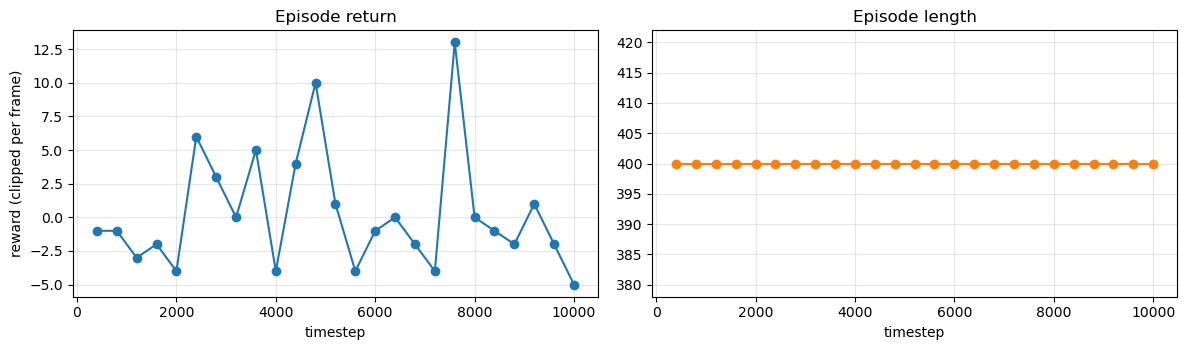

In [8]:
if episodes.returns:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
    ax1.plot(episodes.timesteps, episodes.returns, marker="o")
    ax1.set_title("Episode return")
    ax1.set_xlabel("timestep")
    ax1.set_ylabel("reward (clipped per frame)")
    ax1.grid(alpha=0.3)

    ax2.plot(episodes.timesteps, episodes.lengths, marker="o", color="tab:orange")
    ax2.set_title("Episode length")
    ax2.set_xlabel("timestep")
    ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No episode finished yet - raise N_STEPS_TOTAL to see a curve.")

## 7. Watch the trained agent

Grab RGB frames straight out of the emulator while the policy plays, and show a
strip of the fight.

agent played 400 steps, episode return -4, scoring events 6
final info  : {'health': 70, 'enemy_health': 176, 'score': 1000}


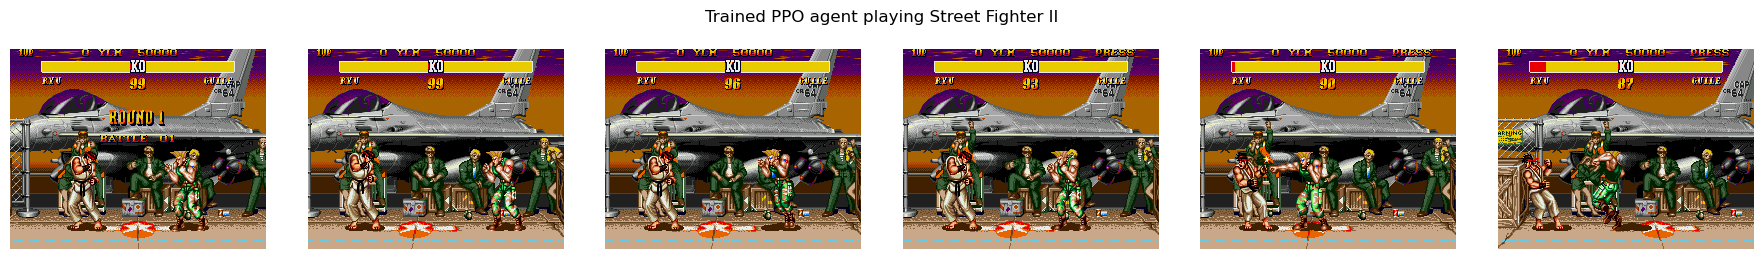

In [9]:
play_env = train_sf2.make_model_env(
    seed=123,
    scenario=SCENARIO,
    max_episode_steps=CFG_MAX_STEPS,
    frame_skip=FRAME_SKIP,
    size=FRAME_SIZE,
    frame_stack=FRAME_STACK,
)
obs, info = play_env.reset(seed=123)

frames, total_reward, hits = [], 0.0, 0
for step in range(CFG_MAX_STEPS):
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = play_env.step(action)
    total_reward += float(reward)
    if reward:
        hits += 1
    if step % 30 == 0 and len(frames) < 6:
        frames.append(play_env.unwrapped.get_screen().copy())
    if terminated or truncated:
        break

print(f"agent played {step + 1} steps, episode return {total_reward:.0f}, "
      f"scoring events {hits}")
print("final info  :", {k: info[k] for k in ("health", "enemy_health", "score")})

fig, axes = plt.subplots(1, len(frames), figsize=(3 * len(frames), 2.6))
for ax, frame in zip(np.atleast_1d(axes), frames):
    ax.imshow(frame)
    ax.axis("off")
fig.suptitle("Trained PPO agent playing Street Fighter II")
plt.tight_layout()
plt.show()
play_env.close()

## 8. Evaluate and save

Deterministic evaluation over a few episodes, then persist the model the same
way the CLI does.

In [10]:
returns = []
for episode in range(N_EVAL_EPISODES):
    env = train_sf2.make_model_env(
        seed=1000 + episode,
        scenario=SCENARIO,
        max_episode_steps=CFG_MAX_STEPS,
        frame_skip=FRAME_SKIP,
        size=FRAME_SIZE,
        frame_stack=FRAME_STACK,
    )
    obs, info = env.reset(seed=1000 + episode)
    done, total, length = False, 0.0, 0
    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        total += float(reward)
        length += 1
        done = terminated or truncated
    env.close()
    returns.append(total)
    print(f"episode {episode + 1}: return {total:.0f}  steps {length}")

print(f"mean return over {N_EVAL_EPISODES} episodes: {np.mean(returns):.1f}")

episode 1: return -4  steps 400


episode 2: return -4  steps 400


episode 3: return -4  steps 400
mean return over 3 episodes: -4.0


In [11]:
os.makedirs(os.path.dirname(MODEL_OUT), exist_ok=True)
model.save(MODEL_OUT)
print("saved:", MODEL_OUT + ".zip")
print("reload with: PPO.load(r'%s.zip', env=...)" % MODEL_OUT)

saved: D:\PROGRAMS\AI\sf2\runs\notebook\sf2_ppo_notebook.zip
reload with: PPO.load(r'D:\PROGRAMS\AI\sf2\runs\notebook\sf2_ppo_notebook.zip', env=...)


## 9. Taking it further

* **Train for real**
  ```powershell
  C:\Users\HEC\miniconda3\python.exe train_sf2.py --timesteps 2000000 --n-envs 4
  ```
  Multi-process (`SubprocVecEnv`) gives ~110 steps/s on this machine vs ~35 here.
* **Reward shaping** — `--scenario health` (default in the CLI) adds damage-based
  reward on top of score; see `scenarios/health.json`.
* **Resume** — `train_sf2.py --resume runs/sf2_ppo/sf2_ppo_final.zip`.
* **Watch it play in a window** —
  `train_sf2.py --play --render --model runs/sf2_ppo/sf2_ppo_final.zip`
* **Play it yourself** — `python play_sf2_human.py` (arrows + Z/X/C/A/S/D).
* **Different ROM release** — add its SHA1 to `rom.sha` and `ROM_STATE_MAP`, then
  run `python make_match_state.py`.